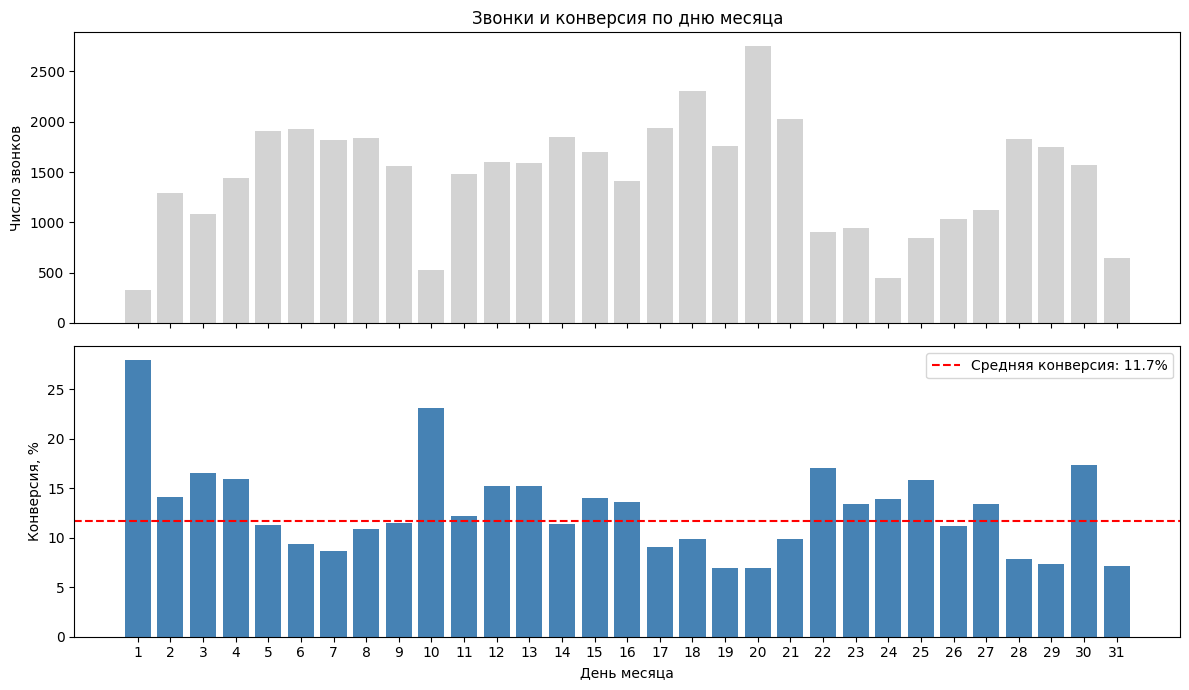

In [19]:
from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt

bank = fetch_ucirepo(id=222)
df = bank.data.features.join(bank.data.targets)
df["target"] = (df["y"] == "yes").astype(int)

day_col = "day_of_week"

by_day = (
    df.groupby(day_col)["target"]
      .agg(calls="count", conversion="mean")
      .reset_index()
)
overall = df["target"].mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

ax1.bar(by_day[day_col], by_day["calls"], color="lightgray")
ax1.set_ylabel("Число звонков")
ax1.set_title("Звонки и конверсия по дню месяца")

ax2.bar(by_day[day_col], by_day["conversion"] * 100, color="steelblue")
ax2.axhline(overall * 100, color="red", linestyle="--",
            label=f"Средняя конверсия: {overall:.1%}")
ax2.set_xlabel("День месяца")
ax2.set_ylabel("Конверсия, %")
ax2.set_xticks(range(1, 32))
ax2.legend()

plt.tight_layout()
plt.show()